# NLP

In [53]:
!pip install wordcloud

In [54]:
# Import Libraries
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

import nltk
from nltk.corpus import stopwords

from wordcloud import WordCloud

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

In [55]:
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HI\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HI\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [56]:
# Load the Dataset
df = pd.read_csv("amazonreviews.tsv", sep="\t")
df.head()

,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,Amazing!: This soundtrack is my favorite music...
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."


In [57]:
# Shape of dataset
df.shape

(10000, 2)

In [58]:
# Size of Dataset
df.size

20000

In [59]:
# columns of Dataset
df.columns

Index(['label', 'review'], dtype='object')

In [60]:
# Dataset Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   10000 non-null  object
 1   review  10000 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB


In [61]:
# Statistical Description
df.describe()

,label,review
count,10000,10000
unique,2,10000
top,neg,Stuning even for the non-gamer: This sound tra...
freq,5097,1


In [62]:
# Check Missing Values
df.isnull().sum()

label     0
review    0
dtype: int64

In [63]:
# Check Duplicate Records
df.duplicated().sum()

np.int64(0)

In [64]:
df['label'].value_counts()

label
neg    5097
pos    4903
Name: count, dtype: int64

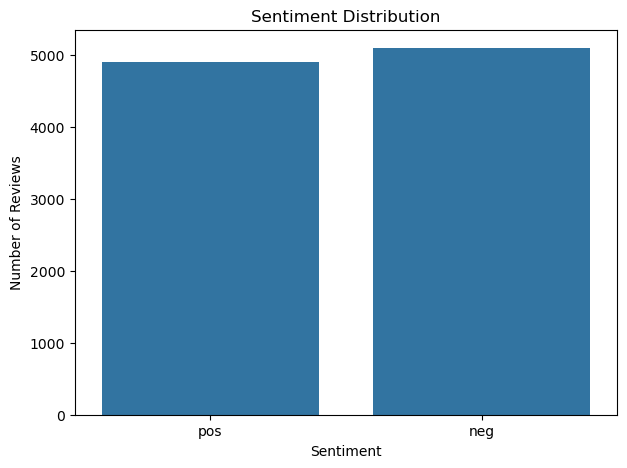

In [65]:
# Plot Sentiment Distribution
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='label')
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [66]:
# Sentiment Distribution in Percentage
sentiment_percentage = df['label'].value_counts(normalize=True) * 100

print(sentiment_percentage)

label
neg    50.97
pos    49.03
Name: proportion, dtype: float64


In [67]:
# Check Review Length
df['review_length'] = df['review'].astype(str).apply(len)
df[['review', 'review_length']].head()

,review,review_length
0,Stuning even for the non-gamer: This sound tra...,426
1,The best soundtrack ever to anything.: I'm rea...,509
2,Amazing!: This soundtrack is my favorite music...,760
3,Excellent Soundtrack: I truly like this soundt...,743
4,"Remember, Pull Your Jaw Off The Floor After He...",481


In [68]:
# Check Number of Words
df['word_count'] = df['review'].astype(str).apply(
    lambda x: len(x.split())
)
df[['review', 'word_count']].head()

,review,word_count
0,Stuning even for the non-gamer: This sound tra...,80
1,The best soundtrack ever to anything.: I'm rea...,97
2,Amazing!: This soundtrack is my favorite music...,129
3,Excellent Soundtrack: I truly like this soundt...,118
4,"Remember, Pull Your Jaw Off The Floor After He...",87


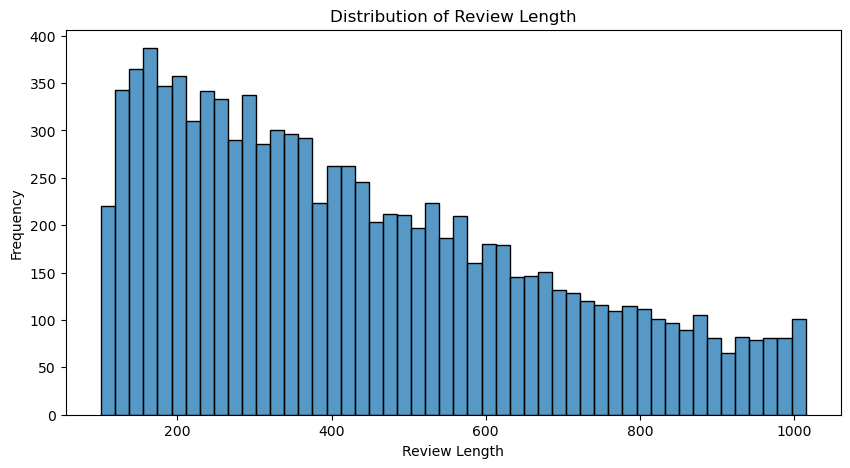

In [69]:
# Review Length Distribution
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='review_length',
    bins=50
)
plt.title("Distribution of Review Length")
plt.xlabel("Review Length")
plt.ylabel("Frequency")
plt.show()

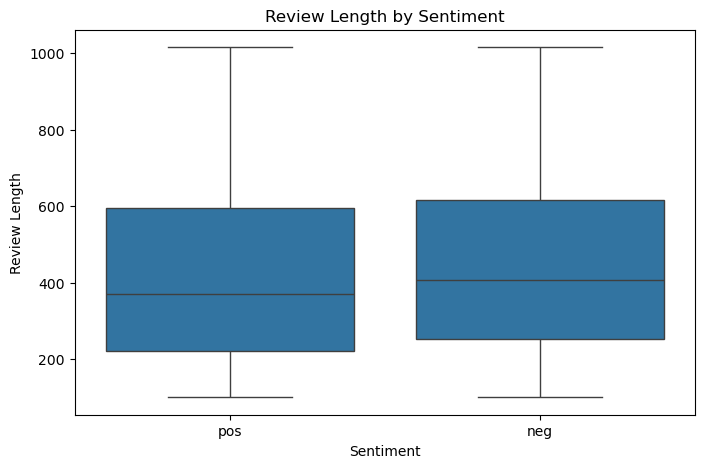

In [70]:
# Review Length by Sentiment
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='label',
    y='review_length'
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Review Length")
plt.show()

#### Text Preprocessing

The assignment specifically requires:

1.Lowercasing
2.Stopword removal
3.Text preprocessing

In [71]:
stop_words = set(stopwords.words('english'))

In [72]:
# Create a cleaning function:
def clean_text(text):
    
    # Convert to lowercase
    text = text.lower()
    
    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    
    # Remove numbers
    text = re.sub(r'\d+', '', text)
    
    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

In [73]:
# Apply Text Cleaning
df['clean_review'] = df['review'].apply(clean_text)
df[['review', 'clean_review']].head(5)

,review,clean_review
0,Stuning even for the non-gamer: This sound tra...,stuning even for the nongamer this sound track...
1,The best soundtrack ever to anything.: I'm rea...,the best soundtrack ever to anything im readin...
2,Amazing!: This soundtrack is my favorite music...,amazing this soundtrack is my favorite music o...
3,Excellent Soundtrack: I truly like this soundt...,excellent soundtrack i truly like this soundtr...
4,"Remember, Pull Your Jaw Off The Floor After He...",remember pull your jaw off the floor after hea...


In [74]:
# Check Cleaned Data
df['clean_review'].isnull().sum()

np.int64(0)

In [75]:
df['clean_review'].head()

0    stuning even for the nongamer this sound track...
1    the best soundtrack ever to anything im readin...
2    amazing this soundtrack is my favorite music o...
3    excellent soundtrack i truly like this soundtr...
4    remember pull your jaw off the floor after hea...
Name: clean_review, dtype: object

In [76]:
# Combine All Positive Reviews
positive_text = ' '.join(
    df[df['label'] == 'pos']['clean_review']
)

In [77]:
# Combine All Negative Reviews
negative_text = ' '.join(
    df[df['label'] == 'neg']['clean_review']
)

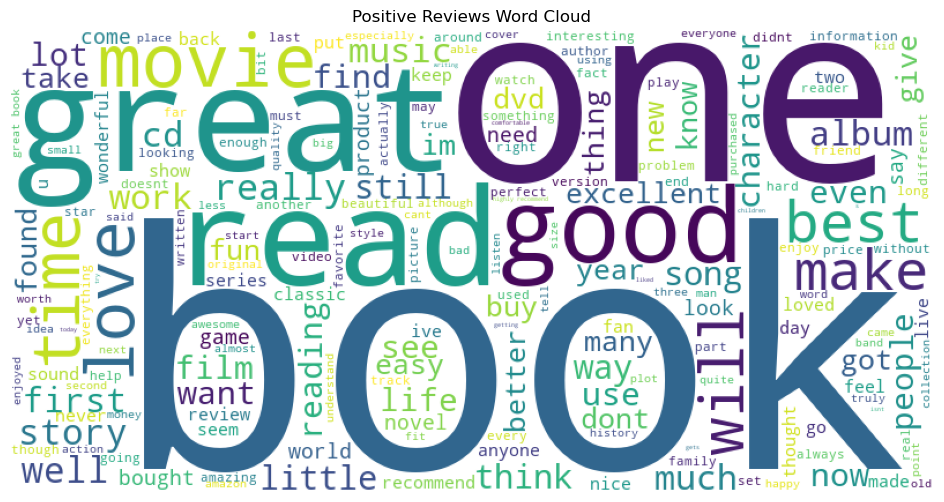

In [78]:
# Positive Word Cloud
positive_text = " ".join(df[df['label']=='pos']['clean_review'])
wordcloud = WordCloud(width=800,height=400,background_color='white').generate(positive_text)
plt.figure(figsize=(12,6))
plt.imshow(wordcloud)
plt.axis("off")
plt.title("Positive Reviews Word Cloud")
plt.show()

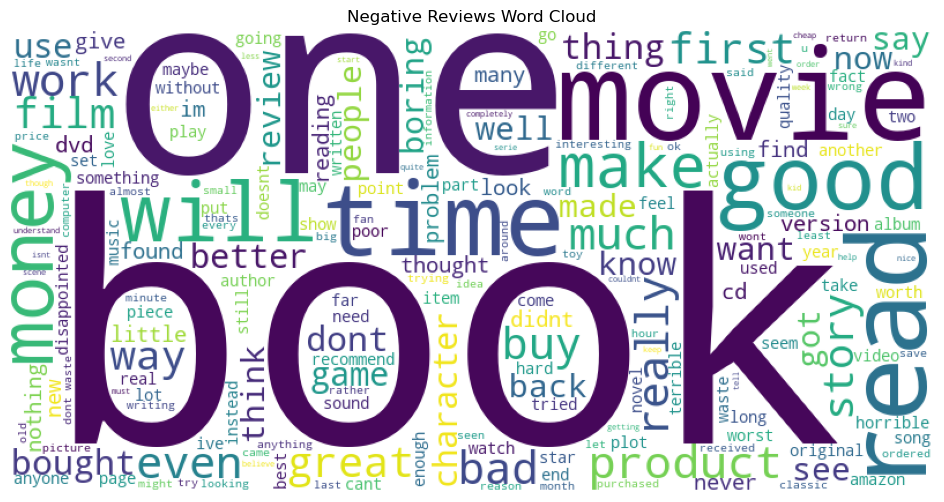

In [79]:
# Negative Word Cloud
negative_text = " ".join(df[df['label']=='neg']['clean_review'])
wordcloud = WordCloud(width=800,height=400,background_color='white').generate(negative_text)
plt.figure(figsize=(12,6))
plt.imshow(wordcloud)
plt.axis("off")
plt.title("Negative Reviews Word Cloud")
plt.show()

In [80]:
# Most Common Positive Words
positive_words = positive_text.split()
positive_counter = Counter(positive_words)
positive_common = positive_counter.most_common(20)
positive_common

[('the', 19066),
 ('and', 11184),
 ('a', 10415),
 ('i', 8869),
 ('to', 8862),
 ('of', 8578),
 ('is', 7320),
 ('it', 7265),
 ('this', 6914),
 ('in', 5050),
 ('for', 4112),
 ('that', 3866),
 ('book', 3313),
 ('you', 3255),
 ('was', 3006),
 ('with', 2747),
 ('my', 2521),
 ('but', 2517),
 ('on', 2517),
 ('as', 2309)]

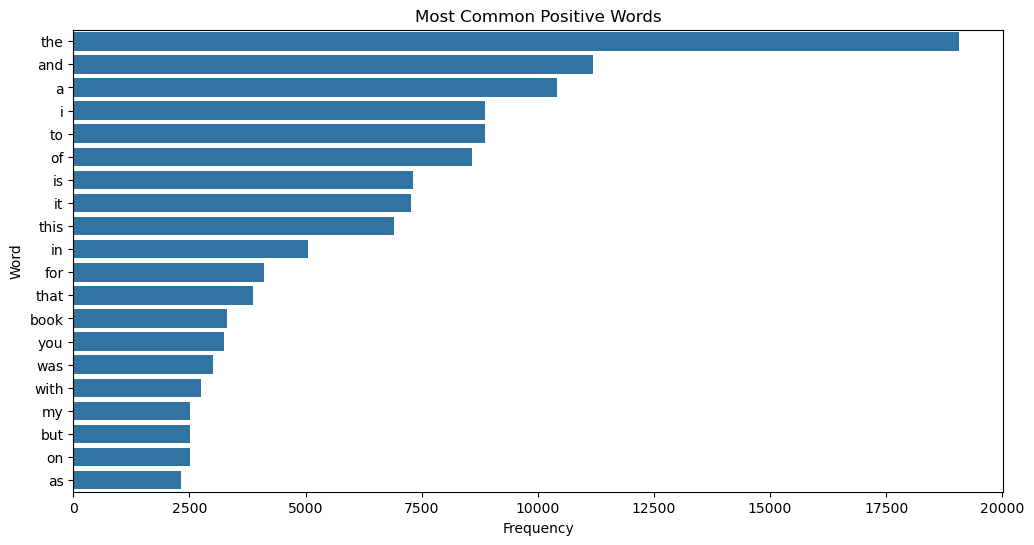

In [81]:
# Plot Most Common Positive Words
positive_df = pd.DataFrame(
    positive_common,
    columns=['word', 'count']
)

plt.figure(figsize=(12,6))
sns.barplot(
    data=positive_df,
    x='count',
    y='word'
)
plt.title("Most Common Positive Words")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

In [82]:
# Most Common Negative Words
negative_words = negative_text.split()
negative_counter = Counter(negative_words)
negative_common = negative_counter.most_common(20)
negative_common

[('the', 21648),
 ('i', 11201),
 ('to', 10382),
 ('and', 10105),
 ('a', 10027),
 ('it', 8805),
 ('this', 8281),
 ('of', 8280),
 ('is', 7261),
 ('in', 4777),
 ('not', 4399),
 ('was', 4376),
 ('that', 4274),
 ('for', 4193),
 ('but', 3272),
 ('book', 3184),
 ('you', 3091),
 ('on', 2997),
 ('with', 2874),
 ('have', 2717)]

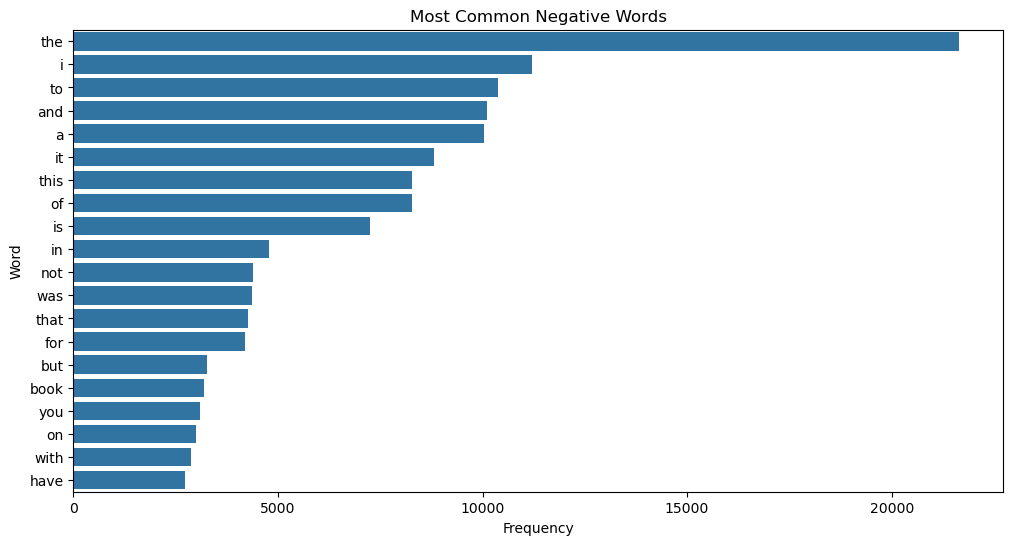

In [83]:
# Plot Most Common Negative Words
negative_df = pd.DataFrame(
    negative_common,
    columns=['word', 'count']
)

plt.figure(figsize=(12,6))
sns.barplot(
    data=negative_df,
    x='count',
    y='word'
)
plt.title("Most Common Negative Words")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

In [84]:
# Prepare X and y ---Features and Target 
X = df['clean_review']
y = df['label']

In [85]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000,)
Testing data: (2000,)


In [86]:
# TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)            # Fit TF-IDF on Training Data
X_test_tfidf = tfidf.transform(X_test)                  # Transform test data
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (8000, 5000)
Testing TF-IDF shape: (2000, 5000)


In [87]:
# Model 1 — Logistic Regression + TF-IDF
lr_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=10000,
    )),
    ('classifier', LogisticRegression(
        max_iter=1000
    ))
])

# Cross-validation
scores = cross_val_score(lr_model,X,y,cv=5,scoring='accuracy')

print("Cross Validation Scores:", scores)
print("Average Accuracy:", scores.mean())

lr_model.fit(X_train,y_train)
lr_pred = lr_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred, pos_label='pos')
lr_recall = recall_score(y_test, lr_pred, pos_label='pos')
lr_f1 = f1_score(y_test, lr_pred, pos_label='pos')

print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)

print("\nclassification_report:\n", classification_report(y_test,lr_pred))

Cross Validation Scores: [0.867  0.844  0.8445 0.8455 0.8615]
Average Accuracy: 0.8525
Accuracy : 0.856
Precision: 0.8539325842696629
Recall   : 0.8521916411824668
F1 Score : 0.8530612244897959

classification_report:
               precision    recall  f1-score   support

         neg       0.86      0.86      0.86      1019
         pos       0.85      0.85      0.85       981

    accuracy                           0.86      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000



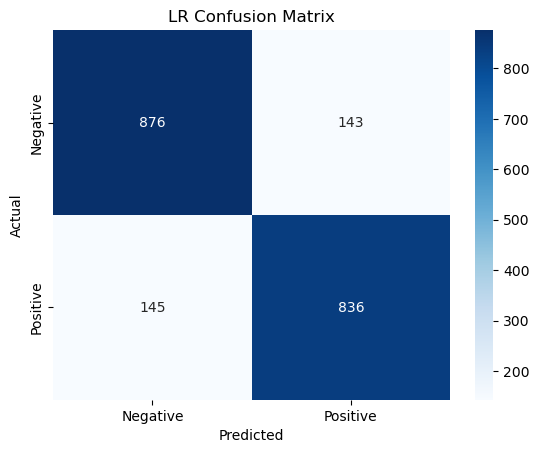

In [88]:
# LR Confusion Matrix
cm = confusion_matrix(y_test,lr_pred)
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LR Confusion Matrix")
plt.show()

In [89]:
# Model 2 — Linear SVM + TF-IDF
svm_model = Pipeline([
    
    ('tfidf', TfidfVectorizer(
        max_features=10000,
    )),
    
    ('classifier', LinearSVC())
])

# Cross-validation
scores = cross_val_score(svm_model,X,y,cv=5,scoring='accuracy')

print("Cross Validation Scores:", scores)
print("Average Accuracy:", scores.mean())

svm_model.fit(X_train,y_train)
svm_pred = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred, pos_label='pos')
svm_recall = recall_score(y_test, svm_pred, pos_label='pos')
svm_f1 = f1_score(y_test, svm_pred, pos_label='pos')

print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)

print("\nclassification_report:\n", classification_report(y_test,svm_pred))

Cross Validation Scores: [0.862  0.833  0.8405 0.8465 0.858 ]
Average Accuracy: 0.8479999999999999
Accuracy : 0.8535
Precision: 0.8539094650205762
Recall   : 0.8460754332313966
F1 Score : 0.8499743983614951

classification_report:
               precision    recall  f1-score   support

         neg       0.85      0.86      0.86      1019
         pos       0.85      0.85      0.85       981

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000



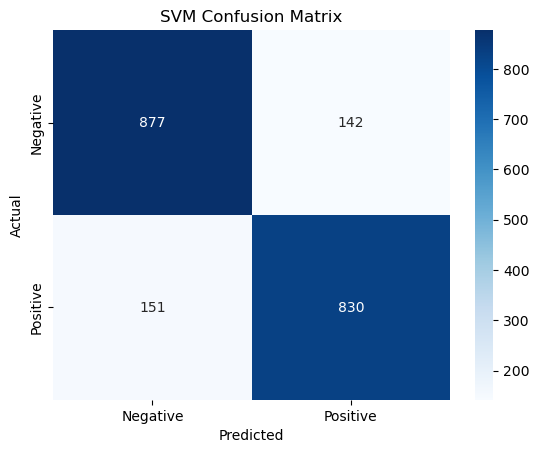

In [90]:
#SVM Confusion Matrix
cm = confusion_matrix(y_test,svm_pred)
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()

In [91]:
# Compare Logistic Regression and SVM
# Create a DataFrame to store model results
results = pd.DataFrame({

    # Model names
    'Model': [
        'Logistic Regression',
        'Linear SVM'
    ],

    # Accuracy of both models
    'Accuracy': [
        lr_accuracy,
        svm_accuracy
    ],

    # Precision of both models
    'Precision': [
        lr_precision,
        svm_precision
    ],

    # Recall of both models
    'Recall': [
        lr_recall,
        svm_recall
    ],

    # F1 Score of both models
    'F1 Score': [
        lr_f1,
        svm_f1
    ]
})

# Display the comparison table
results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8560,0.853933,0.852192,0.853061
1,Linear SVM,0.8535,0.853909,0.846075,0.849974


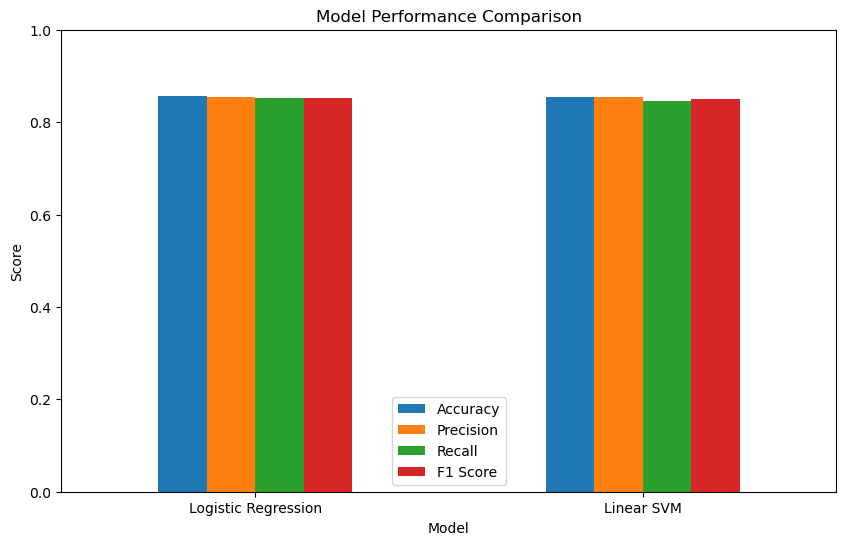

In [92]:
# Visualize Model Comparison
results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

In [93]:
# Find the Best Model
best_model_name = results.loc[
    results['F1 Score'].idxmax(),
    'Model'
]
print("Best Model:", best_model_name)

Best Model: Logistic Regression


In [94]:
# Predict a New Positive Review
new_review = [
    "This product is amazing and I absolutely love it. "
    "The quality is excellent and I would definitely recommend it."
]
prediction = lr_model.predict(new_review)

if prediction[0] == 'pos':
    print("Positive Review")
else:
    print("Negative Review")

Positive Review


In [95]:
# Predict a New Negative Review
new_review = [
    "This product is terrible and completely disappointing. "
    "The quality is very poor and I would never recommend it."
]

prediction = lr_model.predict(new_review)

if prediction[0] == 'pos':
    print("Positive Review")
else:
    print("Negative Review")

Negative Review


In [96]:
# Create a Prediction Function
def predict_sentiment(review):

    prediction = lr_model.predict([review])

    if prediction[0] == 1:
        return "Positive"
    else:
        return "Negative"

In [97]:
print("""
Objective
**********
Develop an automated sentiment analysis system that classifies Amazon product reviews into Positive or Negative sentiments.

Data Cleaning
**************
Removed duplicate reviews.
Removed missing values.
Converted text to lowercase.
Removed punctuation and numbers.
Removed stopwords.
Applied lemmatization.
Exploratory Data Analysis:
***************************
Checked sentiment distribution.
Generated positive and negative word clouds.
Identified top 20 frequent words in positive and negative reviews.""")


Objective
**********
Develop an automated sentiment analysis system that classifies Amazon product reviews into Positive or Negative sentiments.

Data Cleaning
**************
Removed duplicate reviews.
Removed missing values.
Converted text to lowercase.
Removed punctuation and numbers.
Removed stopwords.
Applied lemmatization.
Exploratory Data Analysis:
***************************
Checked sentiment distribution.
Generated positive and negative word clouds.
Identified top 20 frequent words in positive and negative reviews.


In [101]:
import joblib

joblib.dump(lr_model, "sentiment_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [102]:
import joblib

model = joblib.load("sentiment_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!
